Solve the Landau-Zener problem, given by the Hamiltonian
$$
H(t) = z(t)\sigma_z + x\sigma_x
$$
where $z(t)$ is the driving parameter, and $x$ is a constant which defines the coupling between states.

For a single driving parameter, the $(\alpha,\beta)$-hypermetric reads
$$
\mathcal{G}^{(\alpha,\beta)}_{zz} = \frac{|\langle \psi_0 | \partial_z \hat{H}| \psi_1\rangle|^{\beta}}{|E_1-E_0|^{\alpha}},
$$
and the pulse is obtained by solving the differential equation
$$
\frac{dz(t)}{dt} = \frac{\delta^{(\alpha,\beta)}}{\sqrt{\mathcal{G}^{(\alpha,\beta)}_{zz}}},
$$
where $\delta^{(\alpha,\beta)}$ is fixed by the boundary conditions $z(t=0)=-z_0$ and $z(t=t_\mathrm{f})=z_0$:
$$
\delta^{(\alpha,\beta)} = \frac{1}{t_\mathrm{f}}\int_{z(t=0)}^{z(t=t_\mathrm{f})} dz\,\sqrt{\mathcal{G}^{(\alpha,\beta)}_{zz}}.
$$
For the Landau-Zener problem, the pulse shape only depends on $n_+=(\alpha+\beta)/2$. Here, $z_0/x=10$.

Once the pulse shape is obtained, the time-dependent Schrödinger equation is solved with the initial condition $\ket{\Psi(t=0)}=\ket{\psi_0(t=0)}$, i.e., the ground state of the Hamiltonian at the initial time $H(t=0)$. Finally, the transfer fidelity is given by $\mathcal{F}=|\langle\psi_0(t=t_\mathrm{f})|\Psi(t=t_\mathrm{f})\rangle|^2$. We define the maximum fidelity over the pulse time as $\max_{t_\mathrm{f}} \mathcal{F}(t_\mathrm{f}) = \mathcal{F}(\tilde{t}_\mathrm{f})\equiv\tilde{\mathcal{F}}$.

This notebook reproduces panels (a)-(c) of Fig. 2. Panels (d)-(e) are obtained in the notebook `Fig02de-LZ_dephasing.ipynb`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from HQUAD_lib.QUAD_utils import solve_LZ
from HQUAD_lib.parallel_utils import parameter_run
from HQUAD_lib.plotting_utils import plot_gradient_lines
from HQUAD_lib.physics_utils import fidelity_LZ

# Pulses shape

In [2]:
x = 1

n_alphas = 101
alphas = np.linspace(-4, 4, n_alphas)
alphas[0] = -np.inf
alphas[-1] = np.inf

betas = alphas

zs_sol = parameter_run(solve_LZ, [["alpha", "beta"]], [[alphas, betas]], x=x)

solve_LZ: [['alpha', 'beta']]:   0%|          | 0/101 [00:00<?, ?it/s]

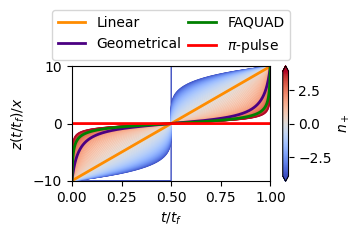

In [3]:
fig, ax = plt.subplots(1, 1, figsize=(3.2, 1.5))
s = np.linspace(0, 1, len(zs_sol[0]))

ax, sm, cbar = plot_gradient_lines(
    s,
    zs_sol,
    alphas,
    betas,
    x_label=r"$t / t_f$",
    y_label=r"$z(t/t_f) / x$",
    cbar_label=r"$n_+$",
    ax=ax,
    cbar_bool=True,
)

ax.legend(
    frameon=True,
    bbox_to_anchor=(-0.1, 1.05, 1.2, 0.2),
    loc="lower left",
    mode="expand",
    borderaxespad=0,
    ncol=2,
);

# Fidelity and pulse times

In [ ]:
def compute_fidelity_total(alpha, beta):
    pulse = solve_LZ(alpha, beta, x=x)

    fidelitites = parameter_run(
        fidelity_LZ, "tf", tfs, pulse=pulse, x=x, z0=-10, pbar_kwargs=dict(leave=False)
    )
    return fidelitites

In [ ]:
tfs = np.linspace(0.1, 10, 25)

n_alphas = 5  # Increase for higher resolution
alphas = np.linspace(-5, 5, n_alphas)
betas = alphas

fidelities = np.zeros((n_alphas, n_alphas, len(tfs)))
pbar = tqdm(total=n_alphas**2, desc="Computing fidelitites")
for i in range(n_alphas):
    for j in range(n_alphas):
        fidelities[i, j] = compute_fidelity_total(alphas[i], betas[j])
        pbar.update()
pbar.close()

Computing fidelitites:   0%|          | 0/25 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/25 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/25 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/25 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/25 [00:00<?, ?it/s]

...

fidelity_LZ: [['tf']]:   0%|          | 0/25 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/25 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/25 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/25 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/25 [00:00<?, ?it/s]

In [6]:
max_fidelity = np.max(fidelities, axis=2)
tf_tilde = tfs[np.argmax(fidelities, axis=2)]

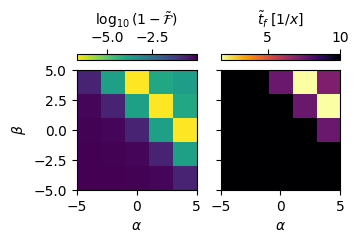

In [ ]:
fig, axs = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(3.4, 2.6))

im = axs[0].imshow(
    np.log10(1 - max_fidelity.T),
    origin="lower",
    aspect="equal",
    interpolation="none",
    extent=[min(alphas), max(alphas), min(betas), max(betas)],
    cmap="viridis_r",
)
cbar0 = plt.colorbar(
    im, ax=axs[0], label=r"$\log_{10}(1 - \tilde{\mathcal{F}})$", location="top"
)

im = axs[1].imshow(
    tf_tilde.T,
    origin="lower",
    aspect="equal",
    interpolation="none",
    extent=[min(alphas), max(alphas), min(betas), max(betas)],
    cmap="inferno_r",
)
cbar1 = plt.colorbar(im, ax=axs[1], label=r"$\tilde{t}_f \; [1 / x]$", location="top")

axs[0].set_ylabel(r"$\beta$")
for ax in axs:
    ax.set_xlabel(r"$\alpha$")